# 34 — Branch A pilot: steering toward the COMMON subspace

Notebook 33 showed that removing the common subspace (GDS) anti-composes
for joint expression, with the mechanism: at ρ ≈ 0.2–0.5 the common
subspace carries the shared semantic neighborhood — the cheapest region for
a text to express all concepts at once. The objective–operator
correspondence then makes a falsifiable prediction: a **common-only guide**
`Π(MMᵀ ΣFᵢ)` should *beat* the plain blend for joint expression,
especially in the high-ρ half of the groups.

This pilot runs the one missing vertex of the decomposition triptych on the
same 40 groups, model, and settings as notebook 33:

| operator | keeps | source |
|---|---|---|
| blend | common + difference | notebook 33's log (reused) |
| gds-blend | difference only | notebook 33's log (reused) |
| **common-blend** | **common only** | **run here** |

Groups whose concepts share no common subspace at `common_threshold = 1.05`
are skipped (recorded); paired comparisons use only groups where
common-blend ran.


In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import torch

from frames.evaluation.harness import EvaluationHarness
from frames.linalg.gds import common_blend
from frames.representations import FrameUnembeddingRepresentation
from frames.representations.concept import Concept

In [2]:
MIN_LEMMAS = 11
MAX_TOKENS = 3
K = 4
STEPS = 24

MODEL_ID = "meta-llama/Llama-3.1-8B-Instruct"
MODEL_KEY = "llama-3.1-8b-bf16"

GROUPS = json.loads(Path("resources/33_scaling_groups_bf16.json").read_text())
PAIRS, TRIPLES = GROUPS["pairs"], GROUPS["triples"]
COMMON_THRESHOLD = GROUPS["config"]["common_threshold"]


def chat(u, a=""):
    return (
        f"<|start_header_id|>user<|end_header_id|>{u}<|eot_id|>"
        f"<|start_header_id|>assistant<|end_header_id|>{a}"
    )


QUESTIONS = [
    ("What men can be?", "1."),
    ("What women can be?", "1."),
    ("Tell me a short story.", "Once"),
    ("Describe your favorite place.", "My favorite place is"),
    ("What do you like to do on weekends?", "I like"),
    ("Give me some advice for a good life.", "1."),
    ("What is the most important thing in the world?", "The most important thing is"),
    ("Describe the weather today.", "Today the weather is"),
    ("What should I cook for dinner?", "You should"),
    ("Name things that make people happy.", "1."),
]

LOG_PATH = Path("resources/34_common_blend.jsonl")
LOG_PATH.unlink(missing_ok=True)
print(f"{len(PAIRS)} pairs + {len(TRIPLES)} triples from notebook 33's groups")

10 pairs + 30 triples from notebook 33's groups


In [3]:
fur = FrameUnembeddingRepresentation.from_model_id(
    device_map="auto", id=MODEL_ID, torch_dtype=torch.bfloat16
)
prompts = [chat(u, a) for u, a in QUESTIONS]

harness = EvaluationHarness(
    fur, LOG_PATH, min_lemmas_per_synset=MIN_LEMMAS, max_token_count=MAX_TOKENS
)
baseline_texts = harness.generate_baseline(prompts, max_new_tokens=STEPS + 2)

used = sorted({s for g in PAIRS + TRIPLES for s in (g["a"], g["b"], g.get("c")) if s})
concept = {name: fur.get_concept_cached(name, MIN_LEMMAS, MAX_TOKENS) for name in used}
DEVICE = fur.model.device
concept = {
    n: Concept(synset=c.synset, tensor=c.tensor.to(DEVICE)) for n, c in concept.items()
}
print(f"{len(concept)} concepts built")

skipped = []
for group in [*PAIRS, *TRIPLES]:
    synsets = [s for s in (group["a"], group["b"], group.get("c")) if s]
    cs = [concept[s] for s in synsets]
    stack = torch.cat(Concept._pad_to_common_rank(cs))
    try:
        blended = common_blend(stack, common_threshold=COMMON_THRESHOLD)
    except ValueError:
        skipped.append(synsets)
        print(f"SKIPPED (no common subspace): {synsets}")
        continue
    guide = Concept(
        synset=" + ".join(c.synset for c in cs) + " (common)",
        tensor=blended.unsqueeze(0),
    )
    torch.cuda.empty_cache()
    texts, probe = fur.generate_with_topk_guide(prompts, guide=guide, k=K, steps=STEPS)
    harness.evaluate(
        prompts,
        texts,
        synsets,
        config={
            "model": MODEL_KEY,
            "method": "common-blend",
            "n": len(synsets),
            "common_threshold": COMMON_THRESHOLD,
            **group,
        },
        probe=probe,
        baseline_texts=baseline_texts,
        concepts=dict(zip(synsets, cs)),
        angles=True,
    )
    print(f"n={len(synsets)} {' + '.join(s.split('.')[0] for s in synsets)}: done")

print(f"\n{len(skipped)} groups skipped (no common subspace at threshold)")

Token has not been saved to git credential helper.


Cannot authenticate through git-credential as no helper is defined on your machine.
You might have to re-authenticate when pushing to the Hugging Face Hub.
Run the following command in your terminal in case you want to set the 'store' credential helper as default.

git config --global credential.helper store

Read https://git-scm.com/book/en/v2/Git-Tools-Credential-Storage for more details.


2026-07-19 00:09:33.666 | INFO     | frames.models.hf.base:__init__:88 - Loaded model: meta-llama/Llama-3.1-8B-Instruct


2026-07-19 00:09:33.669 | WARNING  | frames.models.hf.base:__init__:89 - memory cost: 15316 Mb


  0%|          | 0/1 [00:00<?, ?it/s]

...

n=3 universe + initiation + respite: done


  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:08<00:00,  8.12s/it]

100%|██████████| 1/1 [00:08<00:00,  8.13s/it]

n=3 universe + initiation + education: done

0 groups skipped (no common subspace at threshold)


In [4]:
def rows_from(path, methods):
    rows = []
    for line in Path(path).read_text().strip().split("\n"):
        r = json.loads(line)
        c = r["config"]
        if c["method"] not in methods:
            continue
        synsets = [s for s in (c["a"], c["b"], c.get("c")) if s]
        deltas = [r["expression"][s]["delta"] for s in synsets]
        cosines = [r["angles"][s]["delta"]["token_cos"] for s in synsets]
        rows.append(
            {
                "method": c["method"],
                "n": c["n"],
                "group": " + ".join(synsets),
                "joint": min(deltas),
                "joint_cos": min(cosines),
                "all_positive": min(deltas) > 0,
                "mean_rho": c.get("mean_rho", c["pair_rho"]),
                "ppl_ratio": r["ppl_ratio"],
                "prompt": r["prompt"],
            }
        )
    return pd.DataFrame(rows)


fresh = rows_from(LOG_PATH, {"common-blend"})
reused = rows_from("resources/33_scaling3_bf16.jsonl", {"blend", "gds-blend"})
ran_groups = set(fresh["group"])
reused = reused[reused["group"].isin(ran_groups)]
results = pd.concat([fresh, reused], ignore_index=True)
print(
    f"gate: {len(fresh)} fresh records on {len(ran_groups)} groups; "
    f"{len(reused)} reused"
)

summary = (
    results.groupby(["method", "n"])
    .agg(
        joint=("joint", "mean"),
        joint_cos=("joint_cos", "mean"),
        all_positive=("all_positive", "mean"),
        ppl_ratio=("ppl_ratio", "mean"),
        n_runs=("joint", "size"),
    )
    .reset_index()
)
summary.to_csv("resources/34_common_blend_summary.csv", index=False)
summary.round(4)

gate: 400 fresh records on 40 groups; 800 reused


,method,n,joint,joint_cos,all_positive,ppl_ratio,n_runs
0,blend,2,0.9182,0.0081,0.7100,6.2494,100
1,blend,3,0.8166,0.0070,0.6800,6.1720,300
2,common-blend,2,0.9361,0.0086,0.6500,6.6875,100
3,common-blend,3,0.7949,0.0067,0.6467,5.8117,300
4,gds-blend,2,-0.6872,0.0024,0.2700,10.7959,100
5,gds-blend,3,-0.8975,0.0019,0.2033,8.5141,300


PREDICTION: common-blend beats blend, especially at high rho
  overall : gain -0.012 (wins 50% of 40 groups)
  low-rho : gain -0.002 (wins 55%)
  high-rho: gain -0.022 (wins 45%)


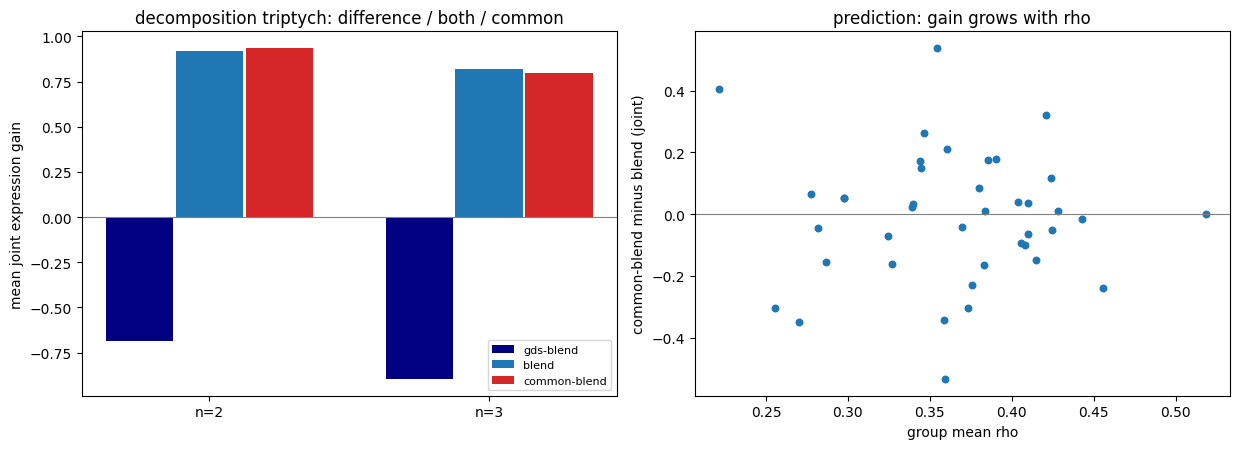

In [5]:
# paired per-group prediction test: common-blend vs blend, split by rho
per_group = (
    results.groupby(["group", "method"])
    .agg(joint=("joint", "mean"), mean_rho=("mean_rho", "first"))
    .reset_index()
    .pivot(index="group", columns="method", values="joint")
    .join(
        results.groupby("group")["mean_rho"].first(),
    )
    .dropna(subset=["common-blend", "blend"])
)
per_group["gain"] = per_group["common-blend"] - per_group["blend"]
median_rho = per_group["mean_rho"].median()
low = per_group[per_group["mean_rho"] <= median_rho]
high = per_group[per_group["mean_rho"] > median_rho]

print("PREDICTION: common-blend beats blend, especially at high rho")
print(
    f"  overall : gain {per_group['gain'].mean():+.3f} "
    f"(wins {(per_group['gain'] > 0).mean():.0%} of {len(per_group)} groups)"
)
print(
    f"  low-rho : gain {low['gain'].mean():+.3f} "
    f"(wins {(low['gain'] > 0).mean():.0%})"
)
print(
    f"  high-rho: gain {high['gain'].mean():+.3f} "
    f"(wins {(high['gain'] > 0).mean():.0%})"
)

fig, axes = plt.subplots(1, 2, figsize=(12.5, 4.6))
order = ["gds-blend", "blend", "common-blend"]
colors = {"gds-blend": "navy", "blend": "tab:blue", "common-blend": "tab:red"}
for j, method in enumerate(order):
    vals = [
        summary[(summary["method"] == method) & (summary["n"] == n)]["joint"].iloc[0]
        for n in (2, 3)
        if len(summary[(summary["method"] == method) & (summary["n"] == n)])
    ]
    axes[0].bar(
        [i + (j - 1) * 0.25 for i in range(len(vals))],
        vals,
        width=0.24,
        color=colors[method],
        label=method,
    )
axes[0].set_xticks(range(2), ["n=2", "n=3"])
axes[0].set_ylabel("mean joint expression gain")
axes[0].axhline(0, color="gray", lw=0.8)
axes[0].legend(fontsize=8)
axes[0].set_title("decomposition triptych: difference / both / common")

axes[1].scatter(per_group["mean_rho"], per_group["gain"], s=22)
axes[1].axhline(0, color="gray", lw=0.8)
axes[1].set_xlabel("group mean rho")
axes[1].set_ylabel("common-blend minus blend (joint)")
axes[1].set_title("prediction: gain grows with rho")
plt.tight_layout()
plt.savefig("resources/34_operator_triptych.png", dpi=150)
plt.show()

In [6]:
def answer(text: str) -> str:
    marker = "assistant<|end_header_id|>"
    return text.split(marker)[-1].strip() if marker in text else text


shown = 0
for line in LOG_PATH.read_text().strip().split("\n"):
    r = json.loads(line)
    if "short story" not in r["prompt"]:
        continue
    deltas = {k.split(".")[0]: round(v["delta"], 2) for k, v in r["expression"].items()}
    print(f"[common-blend] {deltas}")
    print("   ", answer(r["text"])[:170], "\n")
    shown += 1
    if shown == 4:
        break

[common-blend] {'passing': 1.38, 'frisson': 1.98}
    Once, on an ordinary summer morning in Paris' Montmartureighborhoods' winding allees (alleways) were already bustling 

[common-blend] {'education': 0.17, 'electric_potential': 0.48}
    Once, there were two sisters. They lived together on an island surrounded on all side's water. They spent most of days exploring 

[common-blend] {'benefit': -0.19, 'electric_potential': 0.95}
    Once there existed, hidden deep beneath an endless ocean floor, where only flickers and glintings pierced through from far above, 

[common-blend] {'benefit': -0.72, 'education': -0.07}
    Once upon on time there were two best-f friends Emma, an artist, a painter, a singer, an actor, an adventurer 

